# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [65]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [66]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [67]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [68]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [69]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [70]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [71]:
# inspección de plans con .info()

plans.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [72]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [73]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [74]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())
   

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [75]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?

Para el dataset users, se tiene un 11.73% de valores nulos para la columna city, se recomienda imputar con la mediana o el promedio de los datos segun la distribucion presentada. Tambien se recomienda eliminar la columna churn date pues el 88.35% de los datos en esta columna son valores nulos que no aportan para el analisis del dataframe.

Para el dataset usage, la columna duration presenta mas del 50% de datos como nulos, se recomienda imputar con la mediana o promedio de los datos segun la distribucion presentada, de igual forma la columna lenght con mas del 40% de los datos nulos, se recomienda imputar.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [76]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [77]:
users.loc[(users['city'] == '?') | (users['city'] == 'NA'), 'city']

1       ?
83      ?
160     ?
161     ?
186     ?
       ..
3882    ?
3889    ?
3901    ?
3955    ?
3962    ?
Name: city, Length: 96, dtype: object

In [78]:
users['city'].value_counts()

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

In [79]:
users['city'].isna().sum()

469

In [80]:
users.value_counts()

user_id  first_name  last_name  age  city      reg_date                       plan     churn_date 
10032    Carlos      Lopez      44   MTY       2022-01-09 18:17:33.263315829  Premium  1,71832E+18    1
12508    Ana         Torres     54   Medellín  2023-11-18 17:40:49.512378096  Basico   1,72048E+18    1
12743    Luis        Garcia     26   GDL       2026-05-10 00:00:00.000000000  Premium  1,72463E+18    1
12722    Mateo       Gomez      77   MTY       2024-01-16 08:00:43.210802704  Basico   1,72757E+18    1
12715    Carlos      Torres     44   ?         2024-01-14 10:00:37.809452368  Basico   1,73085E+18    1
                                                                                                     ..
11318    Ana         Garcia     41   Bogotá    2022-12-27 21:25:31.282820708  Basico   1,71936E+18    1
11317    Carlos      Lopez      56   Bogotá    2022-12-27 14:51:13.368342088  Basico   1,72826E+18    1
11310    Mateo       Lopez      45   Medellín  2022-12-25 16:51:07.96

In [81]:
users.loc[(users['age']<=0) | (users['age'] == 'NA') | (users['age'] == '?'),'age']

12     -999
146    -999
171    -999
243    -999
297    -999
377    -999
456    -999
509    -999
526    -999
552    -999
606    -999
740    -999
747    -999
754    -999
813    -999
817    -999
864    -999
924    -999
1238   -999
1293   -999
1307   -999
1388   -999
1481   -999
1486   -999
1581   -999
1625   -999
1806   -999
1845   -999
1999   -999
2087   -999
2097   -999
2202   -999
2214   -999
2328   -999
2360   -999
2371   -999
2428   -999
2434   -999
2469   -999
2519   -999
2770   -999
2842   -999
2958   -999
2991   -999
3249   -999
3293   -999
3327   -999
3473   -999
3482   -999
3580   -999
3762   -999
3858   -999
3896   -999
3925   -999
3990   -999
Name: age, dtype: int64

In [82]:
users.loc[(users['first_name'] == 'NA') | (users['first_name'] == '?'),'first_name'].count()

0

In [83]:
users.loc[(users['last_name'] == 'NA') | (users['last_name'] == '?'),'last_name'].count()

0

In [84]:
users.loc[(users['plan'] == 'NA') | (users['plan'] == '?'),'plan'].count()

0

- La columna `user_id` presenta una cantidad de 4000 usuarios registrados. Dicho valor hace match con el rango de usuarios presentados desde el minimo al maximo presentados con la funcion describe()
- La columna `age` presenta una inconsistencia o sentinel que debe ser corregido o imputado, pues su valor minimo es -999.

In [85]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


In [86]:
usage.loc[(usage['date'] == '?') | (usage['date'].isna()), 'date']

2854     NaN
3443     NaN
3808     NaN
3987     NaN
4114     NaN
6287     NaN
6445     NaN
6584     NaN
7879     NaN
8204     NaN
9482     NaN
9692     NaN
11796    NaN
12691    NaN
13610    NaN
14232    NaN
15080    NaN
15696    NaN
16003    NaN
16137    NaN
16383    NaN
17259    NaN
18753    NaN
18955    NaN
19497    NaN
19762    NaN
20060    NaN
21429    NaN
21502    NaN
21867    NaN
22179    NaN
22575    NaN
24085    NaN
25640    NaN
25872    NaN
28203    NaN
28973    NaN
29188    NaN
29933    NaN
31050    NaN
31228    NaN
32797    NaN
33047    NaN
35189    NaN
35518    NaN
36736    NaN
37046    NaN
37535    NaN
38462    NaN
38801    NaN
Name: date, dtype: object

In [87]:
usage.loc[(usage['duration'] == '?') | (usage['duration'].isna()) | (usage['duration'] <=0), 'duration']

1       NaN
2       NaN
8       NaN
9       NaN
11      NaN
         ..
39979   NaN
39981   NaN
39985   NaN
39987   NaN
39998   NaN
Name: duration, Length: 22091, dtype: float64

In [88]:
usage.loc[usage['duration']<= 0, 'duration']

4048     0.0
8073     0.0
9551     0.0
10590    0.0
13951    0.0
17595    0.0
22514    0.0
22519    0.0
23384    0.0
25809    0.0
26974    0.0
27940    0.0
28238    0.0
37177    0.0
37490    0.0
Name: duration, dtype: float64

In [89]:
usage.loc[(usage['length'] == '?') | (usage['length'].isna()) | (usage['length'] <=0), 'length']

0       NaN
3       NaN
4       NaN
5       NaN
6       NaN
         ..
39994   NaN
39995   NaN
39996   NaN
39997   NaN
39999   NaN
Name: length, Length: 18029, dtype: float64

In [90]:
usage.loc[usage['length'] < 0, 'length']

Series([], Name: length, dtype: float64)

- Las columnas `id` y `user_id` muestran  un comportamiento de tabla de hechos. Se encuentran 40000 registros, los cuales representan cada uno de los eventos existentes para los 4000 usuarios ('user_id') registrados para el periodo bajo estudio.
- Las columnas duration y length presentan un comportamiento similar con el promedio un poco mas arriba del percentil 50, tambien se observa que presentan valores maximos bastante grandes en comparacion el percentil 75, esto da una idea clara de presencia de valores atipicos o outliers en ambas columnas.

In [91]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


- La columna `city` presenta 3531 registros no nulos, el 11.73% de los registros en la columna 'city' son datos sentinel o Null. De las 7 ciudades presentes en el dataframe,la ciudad con mas registros es la ciudad de Bogotá con 808 registros.
- La columna `plan` por el contrario cuenta con la totalidad de registros, 4000 registros no nulos, el plan con mas registros es el plan básico con 2595 registros dentro del dataframe users.

In [92]:
# explorar columna categórica de usage
usage['type'].describe()

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

In [93]:
usage['type'].value_counts()

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` presenta dos registros unicos, 'text' y 'call', de los cuales la categoria 'text' tiene 22092 registros que representa mas del 55% de los registros o eventos para el periodo bajo estudio.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
**dataset users**:


**City**: presenta un total de 14.1 % de datos erróneos o faltantes entre los cuales se encontraron valores '?' y valores NaN. 
**age**: presenta 55 valores sentinel -999 que representan el 1.38% de los datos. al tratarse de un porcentaje bajo de valores erróneos se
decide imputar estos valores por la mediana de las edades.

**Dataset usage**:

**date**: tiene 50 valores NaN que representa el 0.125% de los registros de fecha.
**duration**: es tipo de dato numerico y tiene 22076 valores NaN que es el 55.19 % de los datos
**length**: Se encuentran 17896 datos tipo NaN que es el 44.74% de los datos.
- ¿Qué acción tomarías?
- Dataset users:
**city**: Al tratarse de una cantidad considerable de datos no conocidos se imputaran con el valor especial 'unknown' que le ayudara posteriormente al equipo a decidir como actuar sobre dichos datos faltantes.
**age**: Al tratarse de un porcentaje bajo de valores erróneos sedecide imputar estos valores por la mediana de las edades.
- Dataset usage:
**date**: No afectara el análisis y se dejaran como valores NaN
**duration** y **length**: Los datos invalidos o faltantes en ambas columnas son complementarios entre si, es decir una llamada tendra un duration sin un length y viceversa para los mensajes de texto.

  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [94]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors = 'coerce')

In [95]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors= 'coerce')

In [96]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts()

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

En `reg_date`, se encontraron 40 datos fuera de rango, los datos estan registrados hasta el año 2024, pero se encontraron 40 datos para el año 2026.

In [97]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts()

2024.0    39950
Name: date, dtype: int64

En `date` la totalidad de los datos estan concentrados para el año 2024.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
Si, se encontraron registros relacionados con el año 2026, periodo no transcurrido para la fecha del analisis.
- ¿Qué harías con ellas?
 Dichos datos se conservaran como datos NaN para no alterar el analisis de los datos no nulos.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [98]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace([-999], age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [99]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)


# Verificar cambios
users['city'].value_counts()

Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [100]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year == 2026, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts()

2024.0    1330
2023.0    1316
2022.0    1314
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [101]:
# Verificación MAR en usage (Missing At Random) para duration
usage.head(5)


,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [102]:
# Verificación MAR en usage (Missing At Random) para length
usage.head(10)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN
5,6,10473,call,2024-01-01 00:32:34.848871221,4.68,NaN
6,7,12856,call,2024-01-01 00:39:05.818645466,3.27,NaN
7,8,13742,call,2024-01-01 00:45:36.788419710,4.81,NaN
8,9,11530,text,2024-01-01 00:52:07.758193954,NaN,44.0
9,10,12850,text,2024-01-01 00:58:38.727968199,NaN,70.0


Las columnas `duration` y `length` del dataset usage presentan una cantidad de valores invalidos o NaN, debido al tipo de servicio utilizado por el cliente, sea text o call, cada uno presenta una caracteristica que no se emplea en el otro. Es decir una llamada o call tendra duration, sin un valor en length y viceversa para los mensajes de texto o text que cuentan con una longitud de texto o length sin una duracion al tratarse unicamente de envio de caracteres.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [103]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id')['is_text','is_call','duration'].sum().reset_index()
# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [104]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns = {'is_text': 'cant_mensajes', 'is_call': 'cant_llamadas', 'duration': 'cant_minutos_llamada'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [105]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on = ['user_id'], how = 'left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [106]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.122250,5.524381,4.478120,23.317054
std,1154.844867,17.690408,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000
50%,11999.500000,47.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [107]:
# Distribución porcentual del tipo de plan
(user_profile['plan'].value_counts()/4000)*100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

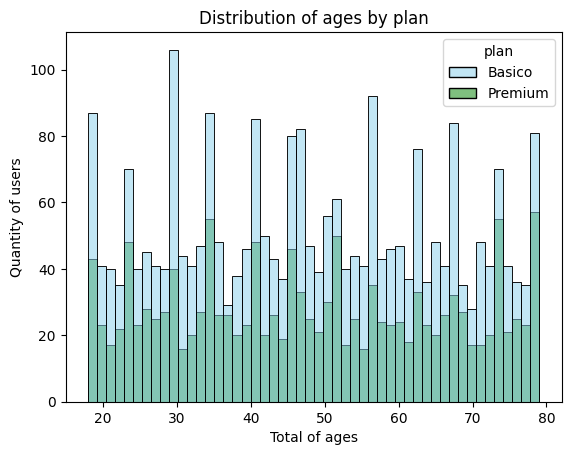

In [108]:
# Histograma para visualizar la edad (age)
sns.histplot(data = user_profile, x = 'age', hue = 'plan', bins = 50, palette = ['skyblue','green'])
plt.title("Distribution of ages by plan")
plt.xlabel('Total of ages')
plt.ylabel('Quantity of users')
plt.show()

💡Insights: 
- Distribución aplanada con bastantes picos, no se observa un patron de simetria o sesgo claro. Para los datasets bajo estudio se encuentran usuarios registrados para un rango amplio de edades desde adolescentes hasta personas de aproximadamente 80 años.

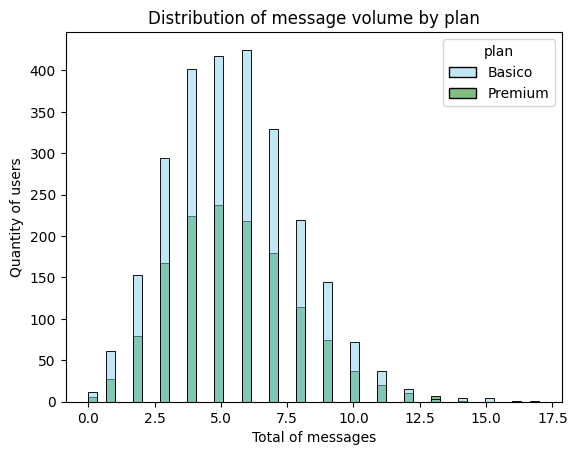

In [109]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data = user_profile, x = 'cant_mensajes', hue = 'plan', bins = 50, palette = ['skyblue', 'green'])
plt.title('Distribution of message volume by plan')
plt.xlabel('Total of messages')
plt.ylabel('Quantity of users')
plt.show()

💡Insights: 
- La cantidad de mensajes procesador durante el periodo bajo estudio tiene una distribución aproximadamente simetrica con sesgo a la derecha, la media y el promedio de esta serie de datos estan bastante cercanos entre si. El limite superior de la serie de datos es 11.5 mensajes. Valor por encima del cual se observan valores atipicos o outliers que alargan la distribucion un poco a la derecha, comportamiento tipico de usuarios con mayor fidelidad y conexion con el servicio.

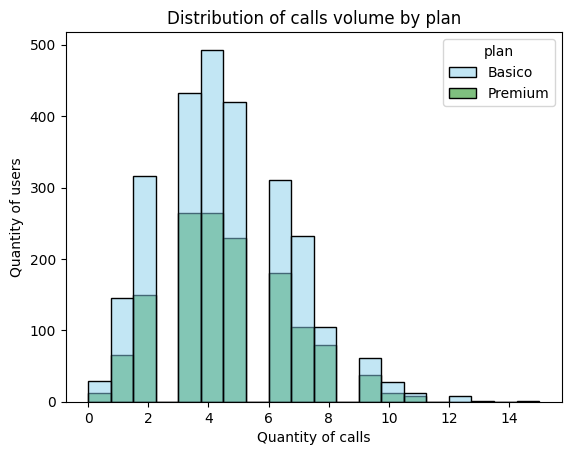

In [110]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data= user_profile, x = 'cant_llamadas', hue = 'plan', bins = 20, palette = ['skyblue', 'green'] )
plt.title('Distribution of calls volume by plan')
plt.xlabel('Quantity of calls')
plt.ylabel('Quantity of users')
plt.show()

💡Insights: 
- La distribucion de los datos para la cantidad de llamadas es bastante similar al obtenido para la cantidad de mensajes, es aproximadamente simetrica con sesgo a la derecha. Con valores atipicos. Los valores atipicos se encuentran por encima de 11 llamadas por usuario. 

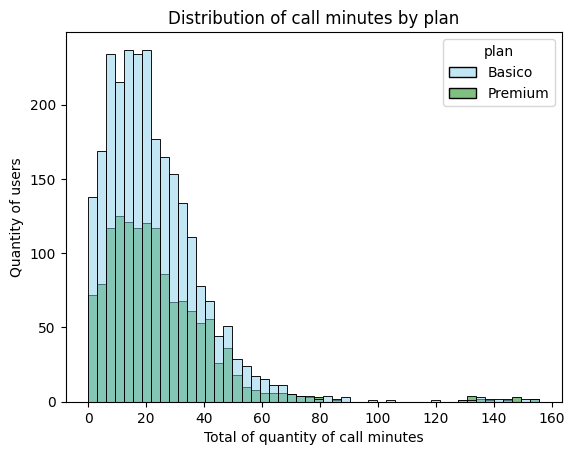

In [111]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data = user_profile, x = 'cant_minutos_llamada', hue= 'plan', bins = 50, palette = ['skyblue', 'green'])
plt.title('Distribution of call minutes by plan')
plt.xlabel('Total of quantity of call minutes')
plt.ylabel('Quantity of users')
plt.show()

💡Insights: 
- La distribución de cant_minutos_llamada presenta un sesgo hacia la derecha, con una mayor concentración de usuarios entre aproximadamente 10 y 30 minutos de llamadas. También se observan casos aislados de consumo elevado, superiores a 100 minutos y cercanos a 155 minutos, que conviene revisar para descartar posibles anomalías. Estos resultados pueden ayudar a ConnectaTel a evaluar la adecuación de sus planes y explorar oportunidades de retención o actualización para usuarios con mayores necesidades de consumo.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

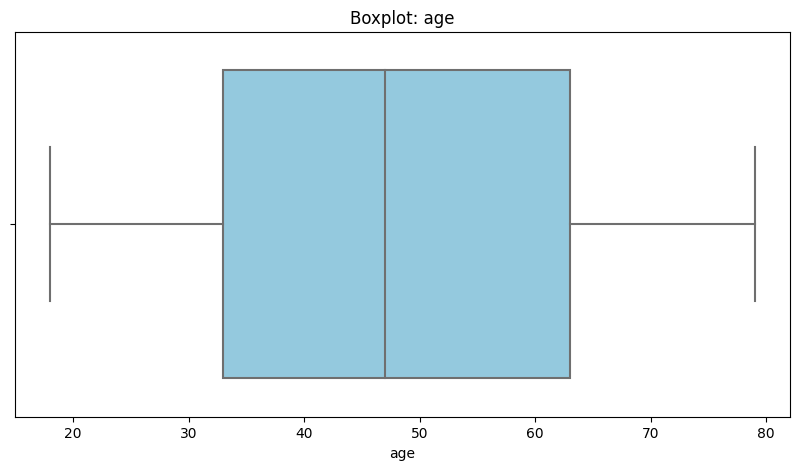

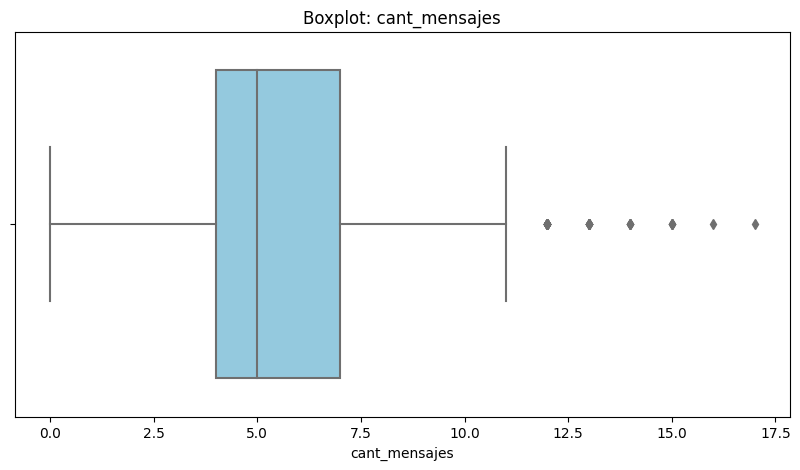

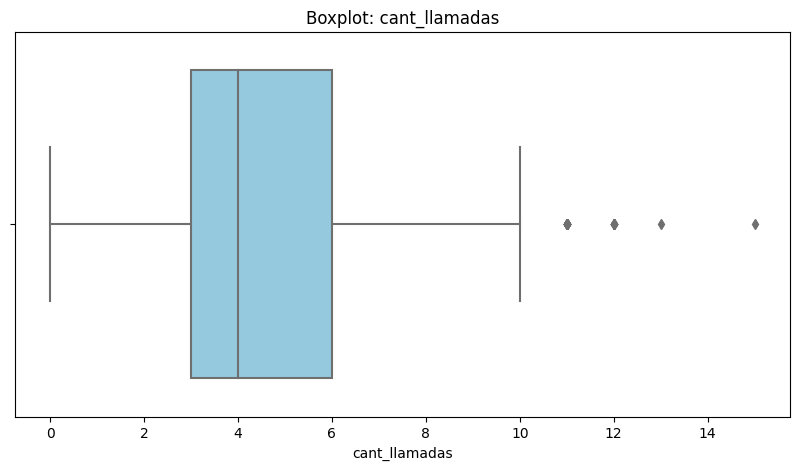

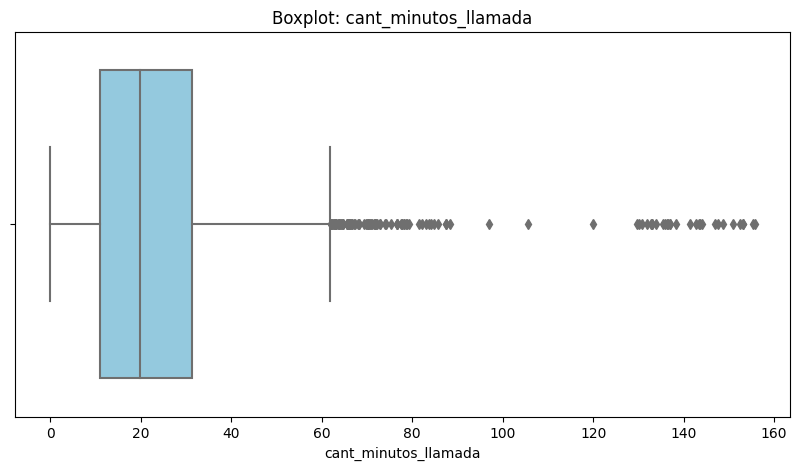

In [112]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

def boxplots(df, columnas_numericas):
    for col in columnas_numericas:
        plt.figure(figsize=(10,5))
        columna = sns.boxplot(data = df, x = col, color = 'skyblue')
        plt.title(f'Boxplot: {col}')
        plt.show()
    return columna

df = boxplots(user_profile, columnas_numericas)

💡Insights: 
- Age: No presenta valores atipicos o outliers. Presenta una grafica aproximadamente simetrica para el conjunto de edades.
- cant_mensajes: Se observan valores atipicos a partir de 11 mensajes.
- cant_llamadas: La cantidad de llamadas tiende a llegar a 10 u 11 aproximadamente. Para los datos se encuentran casos con una cantidad mayor pero bastante cerca al limite  o bigote superior para el boxplot relacionado.
- cant_minutos_llamada: La cantidad de outliers para esta serie de datos es mayor, el boxplot tiene un rango de cantidad de minutos de llamada entre 0 y 62 aproximadamente. Con valores outliers o atipicos que llegan a un poco mas de 155.

In [113]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

def limites(df, columnas_limites):
    for col in columnas_limites:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3-Q1
        top = Q3 + 1.5*IQR
        print(f'El limite superior para {col}, es: {top}')

hallar_limites = limites(user_profile, columnas_limites)


El limite superior para cant_mensajes, es: 11.5
El limite superior para cant_llamadas, es: 10.5
El limite superior para cant_minutos_llamada, es: 61.8575


In [114]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: La cantidad de mensajes atipica no representan valores exagerados o imposibles en la practica, se conservaran dichos datos para el analisis.
- cant_llamadas: La cantidad de llamadas fuera del rango de datos del boxplot siguen siendo una cantidad de llamadas normal, no hay necesidad de winzorizar.
- cant_minutos_llamada: Para este rango de datos se encontraron cantidad de minutos de llamada de mas de dos horas. Aunque no es comun no es anormal o imposible, así que tambien se conservaran dichos outliers o valores atipicos.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [115]:
# Crear columna grupo_uso
user_profile['grupo_uso'] = np.where((user_profile['cant_llamadas'] <5) & (user_profile['cant_mensajes'] <5), 'Bajo uso', np.where((user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10), 'uso medio','Alto uso'))

In [116]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [117]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = np.where(user_profile['age'] < 30, 'Joven', np.where(user_profile['age'] < 60, 'Adulto', 'Adulto mayor'))

In [118]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto mayor


In [119]:

user_profile['grupo_uso_edades'] = np.where((user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
np.where(user_profile['age'] < 30, 'joven bajo uso',
np.where(user_profile['age'] < 60, 'adulto bajo uso',
'adulto mayor bajo uso')),
np.where((user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10),
np.where(user_profile['age'] < 30, 'joven uso medio',
np.where(user_profile['age'] < 60, 'adulto uso medio',
'adulto mayor uso medio')),
np.where(user_profile['age'] < 30, 'joven uso alto',
np.where(user_profile['age'] < 60, 'adulto uso alto',
'adulto mayor uso alto'))))


In [120]:
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad,grupo_uso_edades
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,uso medio,Adulto,adulto uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto,adulto uso alto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,uso medio,Adulto,adulto uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto mayor,adulto mayor uso alto
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto mayor,adulto mayor bajo uso


In [121]:
user_profile['grupo_plan_edades'] = np.where(user_profile['plan'] == 'Basico',
np.where(user_profile['age'] < 30, 'joven plan basico',
np.where(user_profile['age'] < 60, 'adulto plan basico',
'adulto mayor plan basico')),
np.where(user_profile['plan'] == 'Premium',
np.where(user_profile['age'] < 30, 'joven plan premium',
np.where(user_profile['age'] < 60, 'adulto plan premium',
'adulto mayor plan premium')), 'plan desconocido'))

In [122]:
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad,grupo_uso_edades,grupo_plan_edades
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,uso medio,Adulto,adulto uso medio,adulto plan basico
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto,adulto uso alto,adulto plan basico
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,uso medio,Adulto,adulto uso medio,adulto plan basico
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto mayor,adulto mayor uso alto,adulto mayor plan premium
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto mayor,adulto mayor bajo uso,adulto mayor plan basico


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

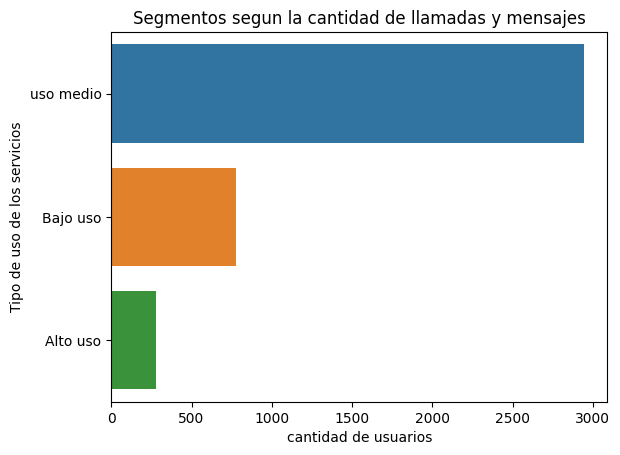

In [123]:
# Visualización de los segmentos por uso
sns.countplot(data = user_profile, y = 'grupo_uso', order = user_profile['grupo_uso'].value_counts().index)
plt.title('Segmentos segun la cantidad de llamadas y mensajes')
plt.ylabel('Tipo de uso de los servicios')
plt.xlabel('cantidad de usuarios')
plt.show()

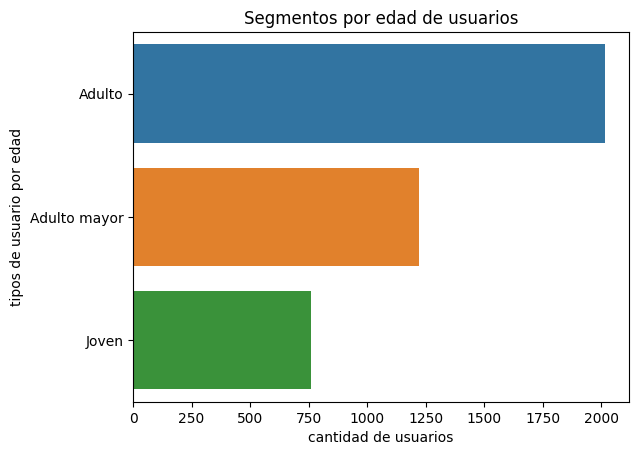

In [124]:
# Visualización de los segmentos por edad
sns.countplot(data = user_profile, y = 'grupo_edad', order = user_profile['grupo_edad'].value_counts().index)
plt.title('Segmentos por edad de usuarios')
plt.ylabel('tipos de usuario por edad')
plt.xlabel('cantidad de usuarios')
plt.show()

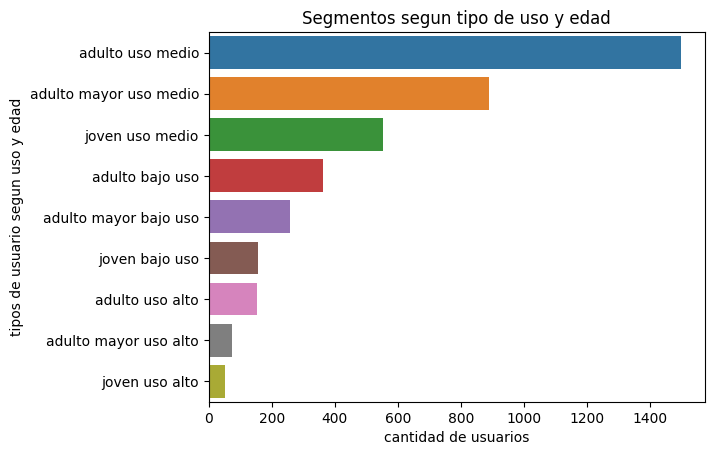

In [125]:



# Visualización de los segmentos combinando grupos edad y uso
sns.countplot(data = user_profile, y = 'grupo_uso_edades', order = user_profile['grupo_uso_edades'].value_counts().index)
plt.title('Segmentos segun tipo de uso y edad')
plt.ylabel('tipos de usuario segun uso y edad')
plt.xlabel('cantidad de usuarios')
plt.show()




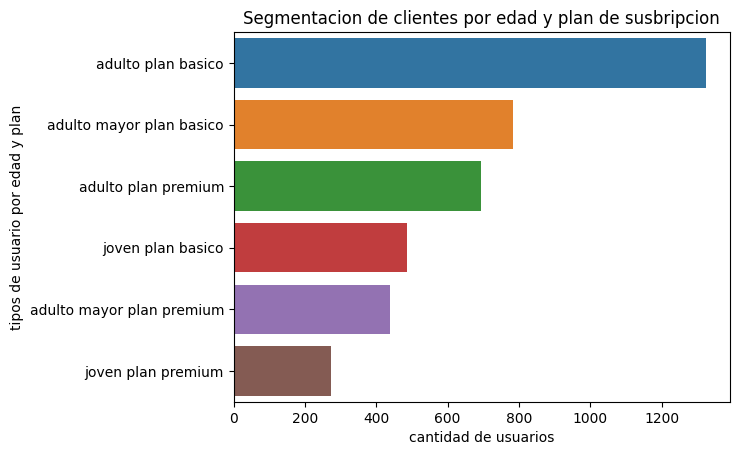

In [126]:
# Visualización de los segmentos combinando grupos plan y edades
sns.countplot(data = user_profile, y = 'grupo_plan_edades', order = user_profile['grupo_plan_edades'].value_counts().index)
plt.title('Segmentacion de clientes por edad y plan de susbripcion')
plt.ylabel('tipos de usuario por edad y plan')
plt.xlabel('cantidad de usuarios')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
Los datos originales de ConnectaTel presentaban problemas de calidad, principalmente valores nulos, datos inválidos o sentinels, valores atípicos e inconsistencias en las fechas.

Dataset users: la columna city tenía aproximadamente un 14,1 % de datos faltantes o inválidos, incluyendo valores NaN y ?. La columna age presentaba 55 valores sentinel de -999 (1,38 %). Además, reg_date contenía 40 registros con fechas del año 2026, fuera del periodo de análisis establecido.

Dataset usage: la columna date tenía 50 valores nulos (0,125 %); duration presentaba 22.076 valores nulos (55,19 %), y length, 17.896 (44,74 %). También se identificaron valores extremos en las variables numéricas duration y length.

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
Se identificaron tres grupos por edad: jóvenes (menores de 30 años), adultos (30 a 59 años) y adultos mayores (60 años en adelante). Al cruzarlos con el nivel de uso, los adultos concentran la mayor cantidad de usuarios de uso medio, seguidos por los adultos mayores y los jóvenes. Los segmentos de uso alto son considerablemente más pequeños, mientras que el uso bajo también tiene mayor presencia entre los adultos.

Al cruzar la edad con el plan de suscripción, el plan Básico predomina en los tres grupos etarios, especialmente entre los adultos, seguido por los adultos mayores. El plan Premium tiene menor participación, aunque también presenta una presencia importante entre los adultos.
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
Los adultos con uso medio y suscripción Básica parecen ser un segmento estratégico por su tamaño, ya que representan una amplia base de clientes para ConnectaTel. Pueden ofrecer oportunidades de conversión hacia Premium mediante beneficios que respondan a sus necesidades de consumo.

Por otro lado, los usuarios de uso alto, aunque son menos numerosos, merecen atención porque podrían generar mayor consumo de servicios y representar oportunidades de retención o actualización de plan. Sin embargo, para confirmar cuáles son los segmentos más rentables, sería necesario analizar sus ingresos, costos y consumo promedio por plan, no solamente la cantidad de usuarios.
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
Se encontraron outliers típicos del negocio en cantidades de mensajes, cantidades de llamadas y cantidades de minutos de llamada. Motivo por el cual se decidió conservar dichos datos para el presente análisis.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

Los datos originales de ConnectaTel presentaban problemas de calidad, principalmente valores nulos, datos inválidos o sentinels, valores atípicos e inconsistencias en las fechas.

Dataset users: la columna city tenía aproximadamente un 14,1 % de datos faltantes o inválidos, incluyendo valores NaN y ?. La columna age presentaba 55 valores sentinel de -999 (1,38 %). Además, reg_date contenía 40 registros con fechas del año 2026, fuera del periodo de análisis establecido.

Dataset usage: la columna date tenía 50 valores nulos (0,125 %); duration presentaba 22.076 valores nulos (55,19 %), y length, 17.896 (44,74 %). También se identificaron valores extremos en las variables numéricas duration y length.


🔍 **Segmentos por Edad**
- Joven
- Adulto
- Adulto mayor 


📊 **Segmentos por Nivel de Uso**
- Bajo uso
- Uso medio
- Uso alto

Se identificaron tres grupos por edad: jóvenes (menores de 30 años), adultos (30 a 59 años) y adultos mayores (60 años en adelante). Al cruzarlos con el nivel de uso, los adultos concentran la mayor cantidad de usuarios de uso medio, seguidos por los adultos mayores y los jóvenes. Los segmentos de uso alto son considerablemente más pequeños, mientras que el uso bajo también tiene mayor presencia entre los adultos.

Al cruzar la edad con el plan de suscripción, el plan Básico predomina en los tres grupos etarios, especialmente entre los adultos, seguido por los adultos mayores. El plan Premium tiene menor participación, aunque también presenta una presencia importante entre los adultos.

➡️ Esto sugiere que los adultos con uso medio y suscripción Básica parecen ser un segmento estratégico por su tamaño, ya que representan una amplia base de clientes para ConnectaTel. Pueden ofrecer oportunidades de conversión hacia Premium mediante beneficios que respondan a sus necesidades de consumo.


💡 **Recomendaciones**
Se recomienda fortalecer el plan Básico con beneficios adicionales opcionales que incentiven a los adultos de uso medio a migrar hacia Premium, mediante promociones o paquetes de mensajes y llamadas. Para los usuarios de uso alto, sería conveniente evaluar planes Premium con mayores límites de consumo y beneficios de fidelización. Asimismo, se podrían diseñar planes económicos para usuarios de bajo consumo, evitando ofrecer recursos que no necesitan. Finalmente, estas propuestas deberían validarse mediante un análisis de ingresos, costos, consumo promedio y rentabilidad por segmento, así como pruebas piloto que permitan medir su impacto en la conversión y retención de clientes.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`